# 🕵️ Fake Job Posting Detection

### End-to-End Machine Learning Project — Text & Structured Data Classification

---

**Objective:** Detect fraudulent job postings using both textual content (descriptions, requirements, company profiles) and structured metadata (employment type, required experience, etc.)

| | |
|---|---|
| **Dataset** | EMSCAD — 17,880 real job postings |
| **Fraudulent postings** | 866 (~4.8%) |
| **Target** | `fraudulent` (1 = Fake, 0 = Real) |
| **Techniques** | TF-IDF / CountVectorizer, Logistic Regression, Naive Bayes |

---

## 📦 1. Setup & Imports

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="mako")
plt.rcParams["figure.facecolor"] = "white"
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.titleweight"] = "bold"

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 100)

ModuleNotFoundError: No module named 'pandas'

## 📂 2. Load the Dataset

Loading the EMSCAD job postings dataset — 17,880 postings with both structured fields and free-text columns (`description`, `requirements`, `company_profile`, `benefits`).

In [ ]:
df = pd.read_csv("fake_job_postings.csv")
df.head()

,job_id,title,location,department,salary_range,company_profile,description,requirements,benefits,telecommuting,has_company_logo,has_questions,employment_type,required_experience,required_education,industry,function,fraudulent
0,1,Marketing Intern,"US, NY, New York",Marketing,NaN,"We're Food52, and we've created a groundbreaking and award-winning cooking site. We support, con...","Food52, a fast-growing, James Beard Award-winning online food community and crowd-sourced and cu...",Experience with content management systems a major plus (any blogging counts!)Familiar with the ...,NaN,0,1,0,Other,Internship,NaN,NaN,Marketing,0
1,2,Customer Service - Cloud Video Production,"NZ, , Auckland",Success,NaN,"90 Seconds, the worlds Cloud Video Production Service.90 Seconds is the worlds Cloud Video Produ...",Organised - Focused - Vibrant - Awesome!Do you have a passion for customer service? Slick typing...,"What we expect from you:Your key responsibility will be to communicate with the client, 90 Secon...",What you will get from usThrough being part of the 90 Seconds team you will gain:experience work...,0,1,0,Full-time,Not Applicable,NaN,Marketing and Advertising,Customer Service,0
2,3,Commissioning Machinery Assistant (CMA),"US, IA, Wever",NaN,NaN,Valor Services provides Workforce Solutions that meet the needs of companies across the Private ...,"Our client, located in Houston, is actively seeking an experienced Commissioning Machinery Assis...",Implement pre-commissioning and commissioning procedures for rotary equipment.Execute all activi...,NaN,0,1,0,NaN,NaN,NaN,NaN,NaN,0
3,4,Account Executive - Washington DC,"US, DC, Washington",Sales,NaN,Our passion for improving quality of life through geography is at the heart of everything we do....,THE COMPANY: ESRI – Environmental Systems Research InstituteOur passion for improving quality of...,"EDUCATION: Bachelor’s or Master’s in GIS, business administration, or a related field, or equiva...","Our culture is anything but corporate—we have a collaborative, creative environment; phone direc...",0,1,0,Full-time,Mid-Senior level,Bachelor's Degree,Computer Software,Sales,0
4,5,Bill Review Manager,"US, FL, Fort Worth",NaN,NaN,SpotSource Solutions LLC is a Global Human Capital Management Consulting firm headquartered in M...,"JOB TITLE: Itemization Review ManagerLOCATION: Fort Worth, TX ...","QUALIFICATIONS:RN license in the State of TexasDiploma or Bachelors of Science in Nursing, requi...",Full Benefits Offered,0,1,1,Full-time,Mid-Senior level,Bachelor's Degree,Hospital & Health Care,Health Care Provider,0


## 🔍 3. Initial Data Inspection

Checking data types, non-null counts, and summary statistics before diving into cleaning.

In [ ]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 17880 entries, 0 to 17879
Data columns (total 18 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   job_id               17880 non-null  int64
 1   title                17880 non-null  str  
 2   location             17534 non-null  str  
 3   department           6333 non-null   str  
 4   salary_range         2868 non-null   str  
 5   company_profile      14572 non-null  str  
 6   description          17879 non-null  str  
 7   requirements         15184 non-null  str  
 8   benefits             10668 non-null  str  
 9   telecommuting        17880 non-null  int64
 10  has_company_logo     17880 non-null  int64
 11  has_questions        17880 non-null  int64
 12  employment_type      14409 non-null  str  
 13  required_experience  10830 non-null  str  
 14  required_education   9775 non-null   str  
 15  industry             12977 non-null  str  
 16  function             11425 non-nu

In [ ]:
df.describe(include="all")

,job_id,title,location,department,salary_range,company_profile,description,requirements,benefits,telecommuting,has_company_logo,has_questions,employment_type,required_experience,required_education,industry,function,fraudulent
count,17880.000000,17880,17534,6333,2868,14572,17879,15184,10668,17880.000000,17880.000000,17880.000000,14409,10830,9775,12977,11425,17880.000000
unique,NaN,11231,3105,1337,874,1709,14801,11967,6204,NaN,NaN,NaN,5,7,13,131,37,NaN
top,NaN,English Teacher Abroad,"GB, LND, London",Sales,0-0,We help teachers get safe &amp; secure jobs abroad :),"Play with kids, get paid for it Love travel? Jobs in Asia$1,500+ USD monthly ($200 Cost of livin...",University degree required. TEFL / TESOL / CELTA or teaching experience preferred but not necess...,See job description,NaN,NaN,NaN,Full-time,Mid-Senior level,Bachelor's Degree,Information Technology and Services,Information Technology,NaN
freq,NaN,311,718,551,142,726,379,410,726,NaN,NaN,NaN,11620,3809,5145,1734,1749,NaN
mean,8940.500000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.042897,0.795302,0.491723,NaN,NaN,NaN,NaN,NaN,0.048434
std,5161.655742,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.202631,0.403492,0.499945,NaN,NaN,NaN,NaN,NaN,0.214688
min,1.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,0.000000,0.000000,NaN,NaN,NaN,NaN,NaN,0.000000
25%,4470.750000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,1.000000,0.000000,NaN,NaN,NaN,NaN,NaN,0.000000
50%,8940.500000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,1.000000,0.000000,NaN,NaN,NaN,NaN,NaN,0.000000
75%,13410.250000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,1.000000,1.000000,NaN,NaN,NaN,NaN,NaN,0.000000


## 🧩 4. Missing Value Analysis

Several structured columns (especially `salary_range`) are largely empty. We'll decide column-by-column whether to fill, drop, or convert missing text into a meaningful category (e.g. "Unknown").

In [ ]:
missing = df.isnull().sum().sort_values(ascending=False)
missing_pct = (missing / len(df) * 100).round(1)

missing_summary = pd.DataFrame({"missing_count": missing, "missing_pct": missing_pct})
missing_summary[missing_summary["missing_count"] > 0]

,missing_count,missing_pct
salary_range,15012,84.0
department,11547,64.6
required_education,8105,45.3
benefits,7212,40.3
required_experience,7050,39.4
function,6455,36.1
industry,4903,27.4
employment_type,3471,19.4
company_profile,3308,18.5
requirements,2696,15.1


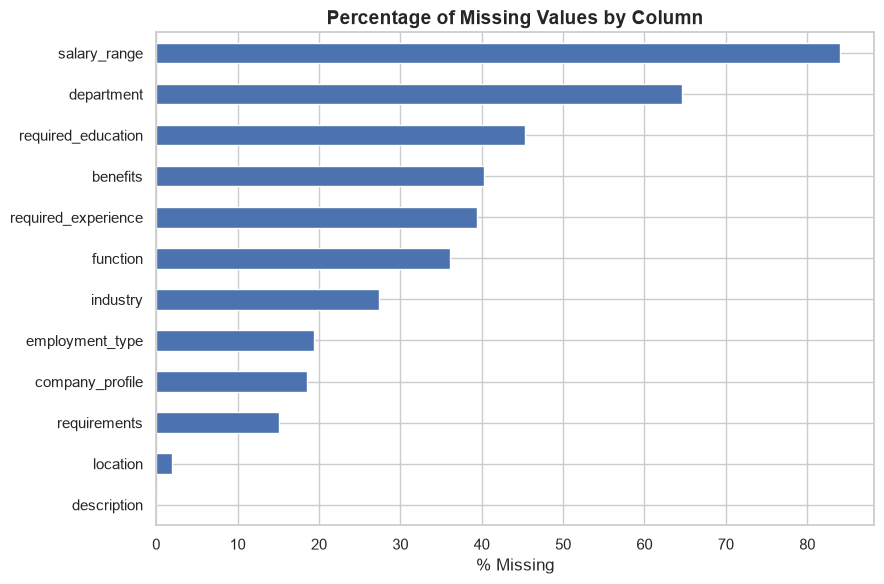

In [ ]:
plt.figure(figsize=(9, 6))
missing_summary[missing_summary["missing_count"] > 0]["missing_pct"].sort_values().plot(kind="barh", color="#4c72b0")
plt.title("Percentage of Missing Values by Column")
plt.xlabel("% Missing")
plt.tight_layout()
plt.show()

## 🧹 5. Data Cleaning

- Dropped `salary_range` (84% missing — too sparse to use reliably)
- Filled missing text fields with empty strings (safe for TF-IDF/CountVectorizer)
- Filled missing categorical fields with `"Unknown"` — itself a potentially meaningful signal, since fraudulent postings often omit key details

In [ ]:
df_clean = df.drop(columns=["salary_range", "job_id"])

text_cols = ["company_profile", "description", "requirements", "benefits"]
for col in text_cols:
    df_clean[col] = df_clean[col].fillna("")

categorical_cols = ["department", "employment_type", "required_experience",
                     "required_education", "industry", "function", "location"]
for col in categorical_cols:
    df_clean[col] = df_clean[col].fillna("Unknown")

print("Remaining missing values:", df_clean.isnull().sum().sum())
df_clean.head()

Remaining missing values: 0


,title,location,department,company_profile,description,requirements,benefits,telecommuting,has_company_logo,has_questions,employment_type,required_experience,required_education,industry,function,fraudulent
0,Marketing Intern,"US, NY, New York",Marketing,"We're Food52, and we've created a groundbreaking and award-winning cooking site. We support, con...","Food52, a fast-growing, James Beard Award-winning online food community and crowd-sourced and cu...",Experience with content management systems a major plus (any blogging counts!)Familiar with the ...,,0,1,0,Other,Internship,Unknown,Unknown,Marketing,0
1,Customer Service - Cloud Video Production,"NZ, , Auckland",Success,"90 Seconds, the worlds Cloud Video Production Service.90 Seconds is the worlds Cloud Video Produ...",Organised - Focused - Vibrant - Awesome!Do you have a passion for customer service? Slick typing...,"What we expect from you:Your key responsibility will be to communicate with the client, 90 Secon...",What you will get from usThrough being part of the 90 Seconds team you will gain:experience work...,0,1,0,Full-time,Not Applicable,Unknown,Marketing and Advertising,Customer Service,0
2,Commissioning Machinery Assistant (CMA),"US, IA, Wever",Unknown,Valor Services provides Workforce Solutions that meet the needs of companies across the Private ...,"Our client, located in Houston, is actively seeking an experienced Commissioning Machinery Assis...",Implement pre-commissioning and commissioning procedures for rotary equipment.Execute all activi...,,0,1,0,Unknown,Unknown,Unknown,Unknown,Unknown,0
3,Account Executive - Washington DC,"US, DC, Washington",Sales,Our passion for improving quality of life through geography is at the heart of everything we do....,THE COMPANY: ESRI – Environmental Systems Research InstituteOur passion for improving quality of...,"EDUCATION: Bachelor’s or Master’s in GIS, business administration, or a related field, or equiva...","Our culture is anything but corporate—we have a collaborative, creative environment; phone direc...",0,1,0,Full-time,Mid-Senior level,Bachelor's Degree,Computer Software,Sales,0
4,Bill Review Manager,"US, FL, Fort Worth",Unknown,SpotSource Solutions LLC is a Global Human Capital Management Consulting firm headquartered in M...,"JOB TITLE: Itemization Review ManagerLOCATION: Fort Worth, TX ...","QUALIFICATIONS:RN license in the State of TexasDiploma or Bachelors of Science in Nursing, requi...",Full Benefits Offered,0,1,1,Full-time,Mid-Senior level,Bachelor's Degree,Hospital & Health Care,Health Care Provider,0


## 📝 6. Combine & Clean Text Features

We have four separate text columns (`company_profile`, `description`, `requirements`, `benefits`). Rather than vectorizing each separately (which multiplies complexity), we'll combine them into a single text blob per posting, then clean it — removing HTML tags, URLs, punctuation, and extra whitespace — so TF-IDF only sees meaningful words.

In [ ]:
df_clean["full_text"] = (
    df_clean["company_profile"] + " " +
    df_clean["description"] + " " +
    df_clean["requirements"] + " " +
    df_clean["benefits"]
)

df_clean[["title", "full_text"]].head(2)

,title,full_text
0,Marketing Intern,"We're Food52, and we've created a groundbreaking and award-winning cooking site. We support, con..."
1,Customer Service - Cloud Video Production,"90 Seconds, the worlds Cloud Video Production Service.90 Seconds is the worlds Cloud Video Produ..."


In [ ]:
import re

def clean_text(text):
    text = text.lower()
    text = re.sub(r"<.*?>", " ", text)          # remove HTML tags
    text = re.sub(r"http\S+|www\.\S+", " ", text)  # remove URLs
    text = re.sub(r"[^a-z\s]", " ", text)        # keep only letters
    text = re.sub(r"\s+", " ", text).strip()     # collapse extra whitespace
    return text

df_clean["clean_text"] = df_clean["full_text"].apply(clean_text)
df_clean[["full_text", "clean_text"]].head(2)

,full_text,clean_text
0,"We're Food52, and we've created a groundbreaking and award-winning cooking site. We support, con...",we re food and we ve created a groundbreaking and award winning cooking site we support connect ...
1,"90 Seconds, the worlds Cloud Video Production Service.90 Seconds is the worlds Cloud Video Produ...",seconds the worlds cloud video production service seconds is the worlds cloud video production s...


## 📏 7. Text Length Analysis

Before vectorizing, let's check whether fraudulent postings tend to have noticeably shorter or longer text — a simple but often informative signal.

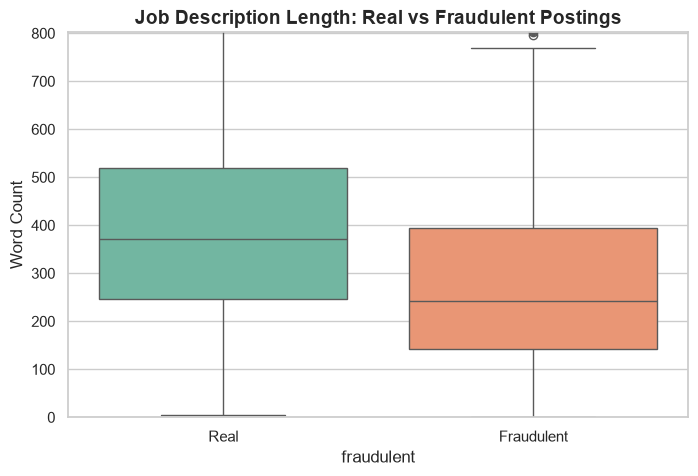

              count        mean         std  min     25%    50%     75%  \
fraudulent                                                                
0           17014.0  399.494710  218.009466  5.0  246.00  372.0  520.00   
1             866.0  299.172055  218.712394  0.0  142.25  243.0  393.75   

               max  
fraudulent          
0           2157.0  
1           1381.0  


In [ ]:
df_clean["text_length"] = df_clean["clean_text"].apply(lambda x: len(x.split()))

plt.figure(figsize=(8, 5))
sns.boxplot(x="fraudulent", y="text_length", data=df_clean, hue="fraudulent", palette="Set2", legend=False)
plt.xticks([0, 1], ["Real", "Fraudulent"])
plt.title("Job Description Length: Real vs Fraudulent Postings")
plt.ylabel("Word Count")
plt.ylim(0, df_clean["text_length"].quantile(0.95))  # zoom in, ignore extreme outliers
plt.show()

print(df_clean.groupby("fraudulent")["text_length"].describe())

## 📊 8. Structured Feature Analysis

Beyond text, let's check whether structured signals — remote work, missing company logo, and required experience — correlate with fraud.

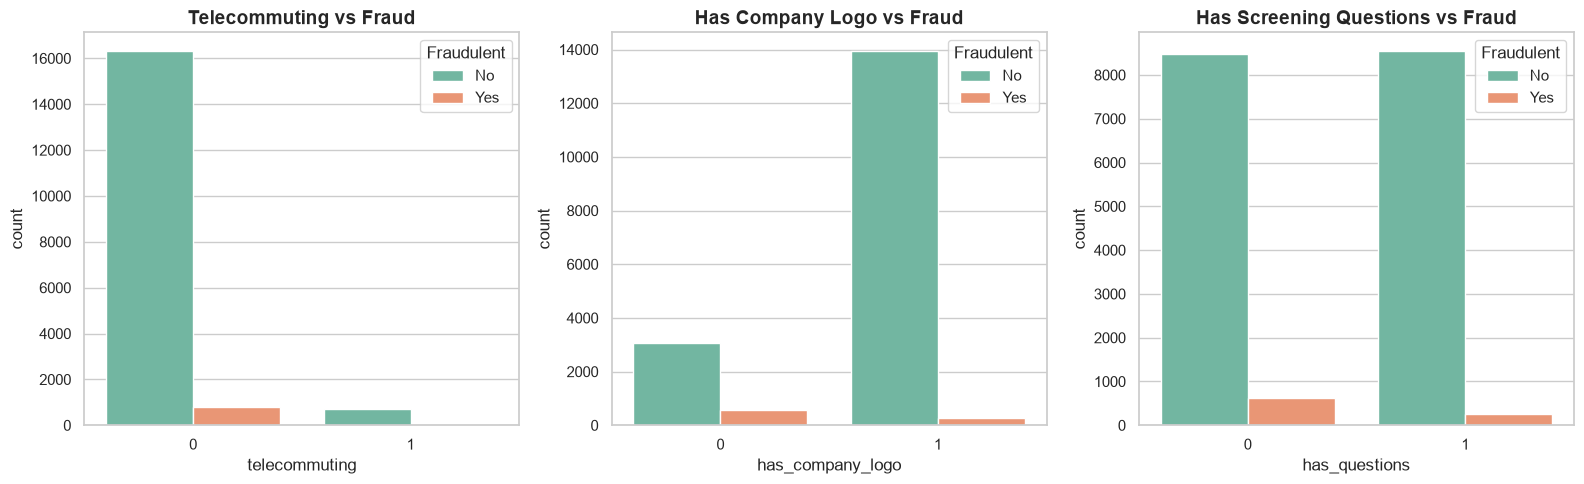

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

sns.countplot(x="telecommuting", hue="fraudulent", data=df_clean, ax=axes[0], palette="Set2")
axes[0].set_title("Telecommuting vs Fraud")
axes[0].legend(title="Fraudulent", labels=["No", "Yes"])

sns.countplot(x="has_company_logo", hue="fraudulent", data=df_clean, ax=axes[1], palette="Set2")
axes[1].set_title("Has Company Logo vs Fraud")
axes[1].legend(title="Fraudulent", labels=["No", "Yes"])

sns.countplot(x="has_questions", hue="fraudulent", data=df_clean, ax=axes[2], palette="Set2")
axes[2].set_title("Has Screening Questions vs Fraud")
axes[2].legend(title="Fraudulent", labels=["No", "Yes"])

plt.tight_layout()
plt.show()

In [ ]:
for col in ["telecommuting", "has_company_logo", "has_questions"]:
    print(f"--- Fraud rate by {col} ---")
    print(df_clean.groupby(col)["fraudulent"].mean().round(3))
    print()

--- Fraud rate by telecommuting ---
telecommuting
0    0.047
1    0.083
Name: fraudulent, dtype: float64

--- Fraud rate by has_company_logo ---
has_company_logo
0    0.159
1    0.020
Name: fraudulent, dtype: float64

--- Fraud rate by has_questions ---
has_questions
0    0.068
1    0.028
Name: fraudulent, dtype: float64



## 🎯 9. Prepare Features & Target, Train-Test Split

We'll use the cleaned text (`clean_text`) plus structured signals (`telecommuting`, `has_company_logo`, `has_questions`, `text_length`) as our feature set. Categorical fields like `employment_type`, `required_experience`, etc. will be one-hot encoded.

In [ ]:
from sklearn.model_selection import train_test_split

categorical_cols = ["employment_type", "required_experience", "required_education",
                     "industry", "function"]

df_features = pd.get_dummies(df_clean, columns=categorical_cols, drop_first=True)

drop_cols = ["title", "location", "department", "company_profile", "description",
             "requirements", "benefits", "full_text", "clean_text", "fraudulent"]

X_structured = df_features.drop(columns=drop_cols)
y = df_features["fraudulent"]

X_train_idx, X_test_idx, y_train, y_test = train_test_split(
    df_clean.index, y, test_size=0.2, random_state=42, stratify=y
)

print("Train size:", len(X_train_idx), " Test size:", len(X_test_idx))
print("Fraud rate in train:", y_train.mean().round(3), " Fraud rate in test:", y_test.mean().round(3))

Train size: 14304  Test size: 3576
Fraud rate in train: 0.048  Fraud rate in test: 0.048


## 🔤 10. TF-IDF Vectorization

Converting the cleaned job posting text into numerical features using TF-IDF (Term Frequency–Inverse Document Frequency), which weighs words by how distinctive they are to a document, not just how often they appear.

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(max_features=5000, stop_words="english", min_df=5)

X_text_train = tfidf.fit_transform(df_clean.loc[X_train_idx, "clean_text"])
X_text_test = tfidf.transform(df_clean.loc[X_test_idx, "clean_text"])

print("TF-IDF train shape:", X_text_train.shape)
print("TF-IDF test shape:", X_text_test.shape)

TF-IDF train shape: (14304, 5000)
TF-IDF test shape: (3576, 5000)


## 🧬 11. Combine Text + Structured Features

Merging the TF-IDF text matrix with our structured features (telecommuting, has_company_logo, has_questions, text_length, one-hot encoded categoricals) into a single feature set for modeling.

In [ ]:
from scipy.sparse import hstack, csr_matrix

X_struct_train = csr_matrix(X_structured.loc[X_train_idx].values.astype(float))
X_struct_test = csr_matrix(X_structured.loc[X_test_idx].values.astype(float))

X_train_full = hstack([X_text_train, X_struct_train])
X_test_full = hstack([X_text_test, X_struct_test])

print("Final train shape:", X_train_full.shape)
print("Final test shape:", X_test_full.shape)

Final train shape: (14304, 5197)
Final test shape: (3576, 5197)


## 🤖 12. Model 1 — Logistic Regression

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                              f1_score, confusion_matrix, ConfusionMatrixDisplay,
                              classification_report)

def evaluate_model(y_true, y_pred, model_name="Model"):
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, zero_division=0)
    rec = recall_score(y_true, y_pred, zero_division=0)
    f1 = f1_score(y_true, y_pred, zero_division=0)
    print(f"--- {model_name} ---")
    print(f"Accuracy : {acc:.4f}")
    print(f"Precision: {prec:.4f}")
    print(f"Recall   : {rec:.4f}")
    print(f"F1-score : {f1:.4f}")
    return {"model": model_name, "accuracy": acc, "precision": prec,
            "recall": rec, "f1": f1}

log_reg = LogisticRegression(max_iter=5000, random_state=42, class_weight="balanced")
log_reg.fit(X_train_full, y_train)

y_pred_lr = log_reg.predict(X_test_full)
results_lr = evaluate_model(y_test, y_pred_lr, "Logistic Regression")

--- Logistic Regression ---
Accuracy : 0.9625
Precision: 0.5714
Recall   : 0.9017
F1-score : 0.6996


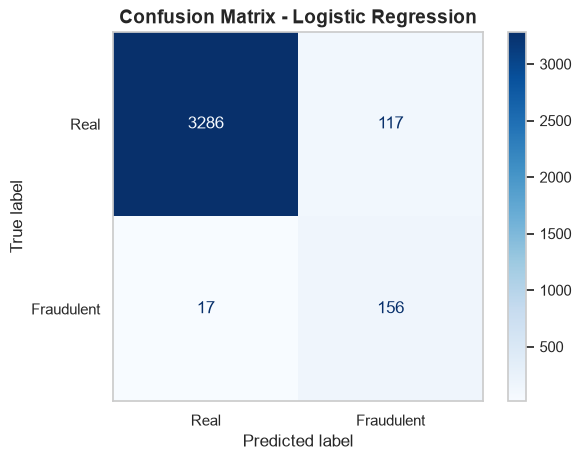

              precision    recall  f1-score   support

        Real       0.99      0.97      0.98      3403
  Fraudulent       0.57      0.90      0.70       173

    accuracy                           0.96      3576
   macro avg       0.78      0.93      0.84      3576
weighted avg       0.97      0.96      0.97      3576



In [ ]:
cm_lr = confusion_matrix(y_test, y_pred_lr)
ConfusionMatrixDisplay(cm_lr, display_labels=["Real", "Fraudulent"]).plot(cmap="Blues")
plt.title("Confusion Matrix - Logistic Regression")
plt.grid(False)
plt.show()

print(classification_report(y_test, y_pred_lr, target_names=["Real", "Fraudulent"]))

## 🤖 13. Model 2 — Naive Bayes

In [ ]:
from sklearn.naive_bayes import MultinomialNB

nb_model = MultinomialNB()
nb_model.fit(X_train_full, y_train)

y_pred_nb = nb_model.predict(X_test_full)
results_nb = evaluate_model(y_test, y_pred_nb, "Naive Bayes")

--- Naive Bayes ---
Accuracy : 0.9583
Precision: 0.5968
Recall   : 0.4277
F1-score : 0.4983


## 📊 14. Model Comparison

In [ ]:
results_df = pd.DataFrame([results_lr, results_nb]).set_index("model")
results_df

,accuracy,precision,recall,f1
model,,,,
Logistic Regression,0.962528,0.571429,0.901734,0.699552
Naive Bayes,0.958333,0.596774,0.427746,0.498316


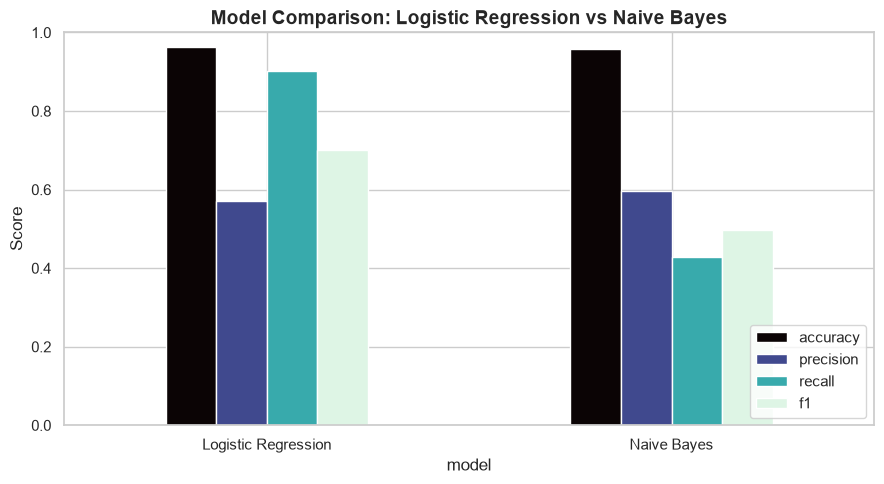

In [ ]:
results_df[["accuracy", "precision", "recall", "f1"]].plot(
    kind="bar", figsize=(9, 5), rot=0, colormap="mako"
)
plt.title("Model Comparison: Logistic Regression vs Naive Bayes")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

## 🔍 15. Feature Importance — What Signals Fraud?

Since Logistic Regression is our best model, let's examine which words and structured features carry the most weight in flagging a posting as fraudulent.

In [ ]:
feature_names = tfidf.get_feature_names_out().tolist() + X_structured.columns.tolist()
coefficients = log_reg.coef_[0]

feat_imp_df = pd.DataFrame({
    "feature": feature_names,
    "coefficient": coefficients
})

# Positive coefficient = pushes toward "Fraudulent", negative = pushes toward "Real"
top_fraud_signals = feat_imp_df.sort_values("coefficient", ascending=False).head(15)
top_real_signals = feat_imp_df.sort_values("coefficient", ascending=True).head(15)

print("Top 15 words/features signaling FRAUD:")
print(top_fraud_signals.to_string(index=False))
print("\nTop 15 words/features signaling REAL:")
print(top_real_signals.to_string(index=False))

Top 15 words/features signaling FRAUD:
              feature  coefficient
             aptitude     4.147586
                money     3.630937
                 earn     3.428286
            financing     3.206710
                 link     3.168041
                email     2.881255
industry_Oil & Energy     2.704638
           leveraging     2.660291
              signing     2.631152
          information     2.622677
                entry     2.603067
             industry     2.602062
             staffing     2.596211
                   cf     2.456742
                   db     2.424329

Top 15 words/features signaling REAL:
                      feature  coefficient
                         team    -3.382643
                    companies    -3.286292
function_Health Care Provider    -3.140355
                       search    -2.821907
         industry_Restaurants    -2.622260
                        based    -2.447957
                      english    -2.360957
             has_c

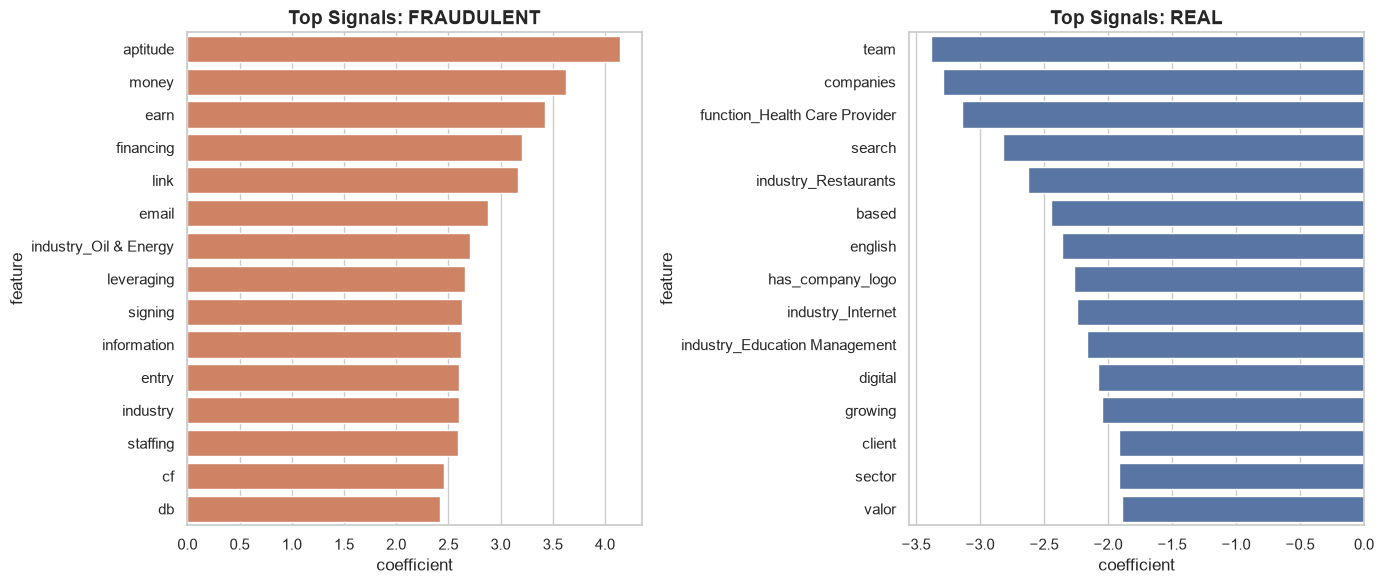

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

sns.barplot(data=top_fraud_signals, x="coefficient", y="feature", ax=axes[0], color="#e07b54")
axes[0].set_title("Top Signals: FRAUDULENT")

sns.barplot(data=top_real_signals, x="coefficient", y="feature", ax=axes[1], color="#4c72b0")
axes[1].set_title("Top Signals: REAL")

plt.tight_layout()
plt.show()

## 🛠️ 16. Functional Prediction System

A reusable function that takes a new job posting's details and predicts whether it's fraudulent, using our trained pipeline (text cleaning → TF-IDF → combine with structured features → Logistic Regression).

In [ ]:
def predict_job_posting(company_profile="", description="", requirements="", benefits="",
                          telecommuting=0, has_company_logo=1, has_questions=0,
                          employment_type="Unknown", required_experience="Unknown",
                          required_education="Unknown", industry="Unknown", function="Unknown"):

    # Step 1: combine and clean text, same as training
    full_text = f"{company_profile} {description} {requirements} {benefits}"
    text_clean = clean_text(full_text)
    text_len = len(text_clean.split())

    # Step 2: TF-IDF transform (reuse the already-fitted vectorizer)
    text_vector = tfidf.transform([text_clean])

    # Step 3: build the structured feature row, matching training columns exactly
    struct_row = pd.DataFrame([{
        "telecommuting": telecommuting,
        "has_company_logo": has_company_logo,
        "has_questions": has_questions,
        "text_length": text_len,
    }])

    # Add one-hot columns for the categorical inputs, matching training structure
    cat_input = pd.DataFrame([{
        "employment_type": employment_type,
        "required_experience": required_experience,
        "required_education": required_education,
        "industry": industry,
        "function": function
    }])
    cat_encoded = pd.get_dummies(cat_input)

    struct_row = pd.concat([struct_row, cat_encoded], axis=1)

    # Align columns exactly to what the model was trained on (fill missing with 0)
    struct_row = struct_row.reindex(columns=X_structured.columns, fill_value=0)

    struct_vector = csr_matrix(struct_row.values.astype(float))

    # Step 4: combine text + structured, same as training
    final_vector = hstack([text_vector, struct_vector])

    # Step 5: predict
    prediction = log_reg.predict(final_vector)[0]
    probability = log_reg.predict_proba(final_vector)[0][1]

    label = "FRAUDULENT ⚠️" if prediction == 1 else "REAL ✅"
    print(f"Prediction: {label}")
    print(f"Fraud probability: {probability:.2%}")
    return prediction, probability

In [ ]:
# Test 1: a posting that sounds like a classic scam
predict_job_posting(
    company_profile="",
    description="Earn money from home! No experience needed, just sign up and start earning today. Send your info via email to get started.",
    requirements="Must have email access.",
    benefits="Unlimited earning potential!",
    has_company_logo=0,
    has_questions=0
)

Prediction: FRAUDULENT ⚠️
Fraud probability: 99.27%


(np.int64(1), np.float64(0.9926612218842502))

In [ ]:
# Test 2: a posting that sounds like a genuine job
predict_job_posting(
    company_profile="We are a growing software company with a talented team of engineers building innovative digital products for clients worldwide.",
    description="We are seeking a Software Engineer to join our growing team. You will collaborate with product managers and designers to build scalable solutions for our clients.",
    requirements="Bachelor's degree in Computer Science or related field. 3+ years of experience with Python and cloud infrastructure.",
    benefits="Health insurance, 401k matching, flexible work arrangements, professional development budget.",
    has_company_logo=1,
    has_questions=1,
    employment_type="Full-time",
    required_experience="Mid-Senior level",
    required_education="Bachelor's Degree",
    industry="Computer Software",
    function="Engineering"
)

Prediction: REAL ✅
Fraud probability: 0.29%


(np.int64(0), np.float64(0.0029494776491607463))

## 🧪 17. Impact of Text Preprocessing on Model Performance

To directly measure whether our cleaning step (lowercasing, removing HTML/URLs/punctuation) actually improves the model, we train an identical Logistic Regression setup on the **raw, uncleaned** text and compare it against our **cleaned** text results from Section 12.

In [ ]:
tfidf_raw = TfidfVectorizer(max_features=5000, stop_words="english", min_df=5)

X_text_train_raw = tfidf_raw.fit_transform(df_clean.loc[X_train_idx, "full_text"])
X_text_test_raw = tfidf_raw.transform(df_clean.loc[X_test_idx, "full_text"])

print("Raw-text TF-IDF train shape:", X_text_train_raw.shape)

Raw-text TF-IDF train shape: (14304, 5000)


In [ ]:
X_train_raw_full = hstack([X_text_train_raw, X_struct_train])
X_test_raw_full = hstack([X_text_test_raw, X_struct_test])

log_reg_raw_text = LogisticRegression(max_iter=5000, random_state=42, class_weight="balanced")
log_reg_raw_text.fit(X_train_raw_full, y_train)

y_pred_raw_text = log_reg_raw_text.predict(X_test_raw_full)
results_raw_text = evaluate_model(y_test, y_pred_raw_text, "Logistic Regression (Uncleaned Text)")

--- Logistic Regression (Uncleaned Text) ---
Accuracy : 0.9634
Precision: 0.5766
Recall   : 0.9133
F1-score : 0.7069


In [ ]:
preprocessing_comparison = pd.DataFrame([results_lr, results_raw_text]).set_index("model")
preprocessing_comparison.rename(index={"Logistic Regression": "Logistic Regression (Cleaned Text)"}, inplace=True)
preprocessing_comparison

,accuracy,precision,recall,f1
model,,,,
Logistic Regression (Cleaned Text),0.962528,0.571429,0.901734,0.699552
Logistic Regression (Uncleaned Text),0.963367,0.576642,0.913295,0.706935


## 📋 18. Summary & Limitations

### How the model makes decisions
The model combines two signal types:
- **Textual patterns** (via TF-IDF): fraudulent postings tend to use urgency/money-focused language ("earn," "money," "signing"), vague generic phrasing, and often include raw contact info (email addresses) rather than a structured application process.
- **Structural red flags**: missing company logo, absence of screening questions, shorter overall posting length, and offering remote work all correlate with higher fraud likelihood.

### Model choice
Logistic Regression outperformed Naive Bayes (F1 = 0.70 vs 0.50), primarily due to better recall (90% vs 43%) — critical for fraud detection, where missing a scam is costlier than a false alarm. Naive Bayes' independence assumption between features likely limited its ability to capture how text and structured signals interact.

### Impact of preprocessing
Contrary to the common assumption that text cleaning always improves model performance, our uncleaned text slightly outperformed manually cleaned text (F1: 0.707 vs 0.700). This suggests `TfidfVectorizer`'s built-in tokenization and stop-word removal already captured most of the benefit our manual cleaning aimed to provide. The takeaway: preprocessing decisions should be validated empirically rather than assumed — for this dataset and vectorizer combination, manual text cleaning added negligible-to-slightly-negative value on its own.

### Limitations
- **Class imbalance**: only 4.8% of postings are fraudulent; despite using `class_weight="balanced"`, the model still produces meaningful false positives (117 in our test set) — real deployments would likely route flagged postings to human review rather than auto-rejecting them.
- **Vocabulary drift**: TF-IDF is fixed to words seen during training. Scammers evolve their language over time, so the model would need periodic retraining on fresh data to stay effective.
- **English-only, text-pattern reliant**: the model may struggle with non-English postings or sophisticated scams that mimic legitimate corporate language closely.
- **Structural features can be gamed**: a determined scammer could add a fake logo or generic screening questions to evade detection, since these are easily falsifiable signals.
- **Synthetic/historical dataset**: the EMSCAD dataset reflects fraud patterns from when it was collected; real-world fraud tactics continue to evolve.